# Relatório de Análise Exploratória (EDA) — Sprint 3

**Projeto Integrador — Inteligência Tributária (Sefin Palmas)**
Entregável E3 | Responsável: Pedro Santos Magalhães Neto

## Objetivo

Explorar a base produzida pelo pipeline `src/etl_sefin.py` (receitas orçamentárias da Prefeitura de Palmas, API `sgreceitas`), descrever seus padrões com estatísticas e gráficos honestos e registrar as limitações que precisam ser resolvidas antes do treinamento do modelo na Sprint 4.

> **Atenção ao escopo.** Os dados coletados são **receitas orçamentárias agregadas** (quanto a prefeitura previu e arrecadou por tipo de receita), **não** débitos individuais de contribuintes. Por isso, esta EDA descreve a **arrecadação**, e não a inadimplência. Os mapas por setor urbano estão em um notebook separado.

## 1. Preparação

Importamos as bibliotecas e localizamos a raiz do repositório, para o notebook funcionar tanto aberto pela pasta `notebooks/` quanto pela raiz.

In [3]:
from pathlib import Path
import subprocess, sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
PASTA_FIGURAS = RAIZ / "docs" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def milhoes(x, pos=None):
    """Formata eixos em milhões de reais (R$ 12,3 mi)."""
    return f"R$ {x/1e6:,.1f} mi".replace(",", "X").replace(".", ",").replace("X", ".")

def salvar(fig, nome):
    fig.savefig(PASTA_FIGURAS / nome, bbox_inches="tight")
    print("Figura salva em docs/figuras/" + nome)

## 2. Carga dos dados

O notebook lê o CSV tratado mais recente em `data/processado/`. Se ele ainda não existir (por exemplo, num clone novo do repositório), o próprio notebook roda o pipeline em modo `--sem-carga`, que não mexe no banco.

In [4]:
def csv_mais_recente():
    arquivos = sorted((RAIZ / "data" / "processado").glob("receitas_tratadas_*.csv"))
    return arquivos[-1] if arquivos else None

if csv_mais_recente() is None:
    print("Nenhum CSV tratado encontrado. Executando o pipeline ETL...")
    subprocess.run([sys.executable, "-m", "src.etl_sefin", "--sem-carga"], cwd=RAIZ, check=True)

ARQUIVO = csv_mais_recente()
df = pd.read_csv(ARQUIVO, sep=";", encoding="utf-8-sig",
                 dtype={"codigo": str, "codigo_original": str})
print("Arquivo:", ARQUIVO.relative_to(RAIZ))
print("Linhas x colunas:", df.shape)
df.head()

Nenhum CSV tratado encontrado. Executando o pipeline ETL...


2026-11-09 02:56:54,553 | INFO | Extraindo: /workspaces/inteligencia_tributaria/data/bruto/coleta_api_20261030_214038.json
2026-11-09 02:56:55,086 | INFO | Transformação: entrada=3000, válidos=3000, rejeitados=0, duplicados=0, grupos_conflitantes=0
2026-11-09 02:56:55,133 | INFO | CSV tratado: /workspaces/inteligencia_tributaria/data/processado/receitas_tratadas_20261109_025654_553404.csv
2026-11-09 02:56:55,133 | INFO | CSV de rejeitados: /workspaces/inteligencia_tributaria/data/rejeitados/receitas_rejeitadas_20261109_025654_553404.csv
2026-11-09 02:56:55,133 | INFO | Modo --sem-carga: nenhuma alteração no banco.
2026-11-09 02:56:55,133 | INFO | Relatório da execução: /workspaces/inteligencia_tributaria/data/processado/resumo_etl_20261109_025654_553404.json | status=sucesso
Arquivo: data/processado/receitas_tratadas_20261109_025654_553404.csv
Linhas x colunas: (3000, 16)


,chave_registro,hash_conteudo,orgao,orgao_nome,unidade_id,unidade_nome,codigo,codigo_original,ano,mes,descricao,valor_orcado,valor_arrecado_mes,valor_arrecado_periodo,covid,linha_origem
0,46b214e1759916b9fc80806ae513b391fc9d0d2468f4f9...,e24d3ba47281a76ad5baf02f68437669e3a73453ead3e3...,2798,TESOURO MUNICIPAL,NaN,NaN,1.0.0.0.00.0.0,1,2026,10,RECEITAS CORRENTES,1.489908e+09,1.018598e+08,1.018598e+08,0,1
1,457ce04bdd7abc4fda3aad852f7461170b54b03c63b8f7...,7f151e35d115459c35ce0fe6d61e254938929b250b3fd8...,2798,TESOURO MUNICIPAL,NaN,NaN,1.1.0.0.00.0.0,11,2026,10,"IMPOSTOS, TAXAS E CONTRIBUIÇÕES DE MELHORIA",6.714153e+08,5.607339e+07,5.607339e+07,0,2
2,4b85ba662456aae5e37bc9f277ea57e4f8f662d82ae3c5...,1b47352f133c24d1fa9889e4e0df072c027a788b55d383...,2798,TESOURO MUNICIPAL,NaN,NaN,1.1.1.0.00.0.0,111,2026,10,IMPOSTOS,6.052328e+08,5.300356e+07,5.300356e+07,0,3
3,56eb364aed40c1866cd3c9f794d88b6a640e12ddcbf5d7...,237c9f6b32d169639a8ee441076de84af9d4660eacabd2...,2798,TESOURO MUNICIPAL,NaN,NaN,1.7.0.0.00.0.0,17,2026,10,TRANSFERÊNCIAS CORRENTES,7.066025e+08,4.502129e+07,4.502129e+07,0,4
4,8028fcbf79814ef5f3bb23888d76abd971851d4f1a9bcf...,d076bd18c76fca2e751213ac166d8bf4071481018fd948...,2798,TESOURO MUNICIPAL,NaN,NaN,1.1.1.4.00.0.0,1114,2026,10,"IMPOSTOS SOBRE A PRODUÇÃO, CIRCULAÇÃO DE MERCA...",3.132125e+08,3.262524e+07,3.262524e+07,0,5


## 3. Visão geral e qualidade dos dados

In [5]:
valores = ["valor_orcado", "valor_arrecado_mes", "valor_arrecado_periodo"]

print("Períodos (ano/mês) e quantidade de linhas:")
print(df.groupby(["ano", "mes"]).size().to_string(), "\n")
print("Órgãos distintos:", df["orgao_nome"].nunique())
print("Valores nulos por coluna (só as que têm algum):")
nulos = df.isna().sum()
print(nulos[nulos > 0].to_string(), "\n")
print("Linhas com arrecadação zero no mês:", (df["valor_arrecado_mes"] == 0).sum())
print("Linhas com valores negativos:", (df[valores] < 0).any(axis=1).sum())
print("arrecadado_periodo == arrecadado_mes em todas as linhas?",
      bool((df["valor_arrecado_periodo"] == df["valor_arrecado_mes"]).all()))

Períodos (ano/mês) e quantidade de linhas:
ano   mes
2026  9      1277
      10     1723 

Órgãos distintos: 39
Valores nulos por coluna (só as que têm algum):
unidade_id      3000
unidade_nome    3000 

Linhas com arrecadação zero no mês: 1215
Linhas com valores negativos: 24
arrecadado_periodo == arrecadado_mes em todas as linhas? True


**Leitura:** as colunas `unidade_id` e `unidade_nome` estão 100% vazias e podem ser descartadas. Cerca de 40% das linhas têm arrecadação zero no mês (rubricas previstas que não receberam nada). As poucas linhas negativas correspondem a **deduções** contábeis, que são normais em orçamento público. As colunas `valor_arrecado_mes` e `valor_arrecado_periodo` são idênticas, então só uma delas precisa ser usada.

### 3.1 Cuidado: os códigos são hierárquicos

O `codigo_original` segue a classificação orçamentária: `1` = Receitas Correntes, `11` = Impostos, Taxas e Contribuições, `111` = Impostos, `1112` = Impostos sobre o Patrimônio, e assim por diante. Cada nível **já contém a soma** dos níveis abaixo dele. **Somar todas as linhas conta o mesmo dinheiro várias vezes.** Por isso, criamos duas marcações:

- `nivel`: quantidade de dígitos do código (1 = categoria, 2 = origem, ...);
- `folha`: `True` quando a linha é a mais detalhada do seu ramo (nenhum outro código do mesmo órgão e mês começa com ela). Somar só as folhas evita a dupla contagem.

In [6]:
df["nivel"] = df["codigo_original"].str.len()

def marcar_folhas(grupo):
    codigos = set(grupo["codigo_original"])
    return grupo["codigo_original"].apply(
        lambda c: not any(o != c and o.startswith(c) for o in codigos))

df["folha"] = df.groupby(["orgao", "ano", "mes"], group_keys=False).apply(marcar_folhas)

soma_tudo = df.loc[df["mes"] == 10, "valor_arrecado_mes"].sum()
soma_folhas = df.loc[(df["mes"] == 10) & df["folha"], "valor_arrecado_mes"].sum()
print(f"Out/2026 somando TODAS as linhas: {milhoes(soma_tudo)}  <- errado (dupla contagem)")
print(f"Out/2026 somando só as FOLHAS:    {milhoes(soma_folhas)}")
print("Linhas-folha:", df["folha"].sum(), "de", len(df))

Out/2026 somando TODAS as linhas: R$ 1.218,4 mi  <- errado (dupla contagem)
Out/2026 somando só as FOLHAS:    R$ 150,9 mi
Linhas-folha: 1036 de 3000


/tmp/ipykernel_3841/428905445.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["folha"] = df.groupby(["orgao", "ano", "mes"], group_keys=False).apply(marcar_folhas)


### 3.2 Cobertura da coleta

A API informa um total de registros muito maior do que o que foi baixado. Verificamos o tamanho dessa diferença.

In [7]:
import json
bruto = sorted((RAIZ / "data" / "bruto").glob("coleta_api_*.json"))[-1]
total_api = int(json.loads(bruto.read_text(encoding="utf-8"))[0]["total"])  # total informado pela API
print(f"Registros disponíveis na API: {total_api:,}".replace(",", "."))
print(f"Registros coletados:          {len(df):,}".replace(",", "."))
print(f"Cobertura: {len(df)/total_api:.1%}")

Registros disponíveis na API: 180.997
Registros coletados:          3.000
Cobertura: 1.7%


**Leitura:** a coleta usa `limite_paginas=3` (3 × 1.000 registros), então baixamos menos de 2% do que a API oferece: só **setembro e outubro de 2026**, e setembro **incompleto** (a coleta parou no meio do mês, em ordem decrescente). Somas de setembro feitas a partir das folhas estariam subestimadas. Para comparar os dois meses com segurança, a análise usa as **linhas de total que o próprio sistema já calcula** (por exemplo, o código `111` – Impostos), que existem completas nos dois meses para o Tesouro Municipal.

Além disso, a coleta foi feita em **30/10/2026**, então outubro pode não estar fechado.

## 4. Estatísticas descritivas

Calculadas sobre as **linhas-folha de outubro/2026** com arrecadação positiva, para não misturar níveis da hierarquia. Setembro fica de fora porque, com a coleta cortada no meio, várias linhas de total aparecem como "folhas" falsas (os filhos delas não foram baixados).

In [8]:
folhas = df[df["folha"] & (df["mes"] == 10) & (df["valor_arrecado_mes"] > 0)]
desc = folhas["valor_arrecado_mes"].describe(percentiles=[.25, .5, .75, .9]).to_frame("out/2026").T
desc_fmt = desc.copy()
for c in desc_fmt.columns:
    if c != "count":
        desc_fmt[c] = desc_fmt[c].map(lambda v: f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
desc_fmt["count"] = desc["count"].astype(int)
desc_fmt

,count,mean,std,min,25%,50%,75%,90%,max
out/2026,234,"R$ 691.408,36","R$ 2.695.494,89","R$ 1,00","R$ 2.923,53","R$ 26.455,97","R$ 192.677,91","R$ 1.289.685,19","R$ 29.442.709,54"


In [9]:
media, mediana = folhas["valor_arrecado_mes"].mean(), folhas["valor_arrecado_mes"].median()
top10 = folhas.nlargest(int(len(folhas) * 0.10), "valor_arrecado_mes")["valor_arrecado_mes"].sum()
print(f"Média / mediana: {media/mediana:,.0f} vezes")
print(f"Os 10% maiores lançamentos concentram {top10/folhas['valor_arrecado_mes'].sum():.1%} do valor")

Média / mediana: 26 vezes
Os 10% maiores lançamentos concentram 83.9% do valor


**Leitura:** a média é dezenas de vezes maior que a mediana, e os 10% maiores lançamentos concentram a grande maioria do valor arrecadado. É uma distribuição extremamente **assimétrica**: poucas rubricas grandes (repasses e impostos principais) e muitas rubricas pequenas. Por isso a média sozinha é enganosa, e os gráficos de distribuição precisam de escala logarítmica.

## 5. Visualizações

Todos os gráficos usam o **Tesouro Municipal** (o órgão que recebe os tributos) e as **linhas de total** do sistema, salvo indicação.

In [10]:
tesouro = df[df["orgao_nome"] == "TESOURO MUNICIPAL"]

def linha(cod, mes):
    r = tesouro[(tesouro["codigo_original"] == cod) & (tesouro["mes"] == mes)]
    return r.iloc[0] if len(r) else None

### Gráfico 1 — Composição: de onde vem a receita corrente (out/2026)

Figura salva em docs/figuras/g1_composicao_receitas.png


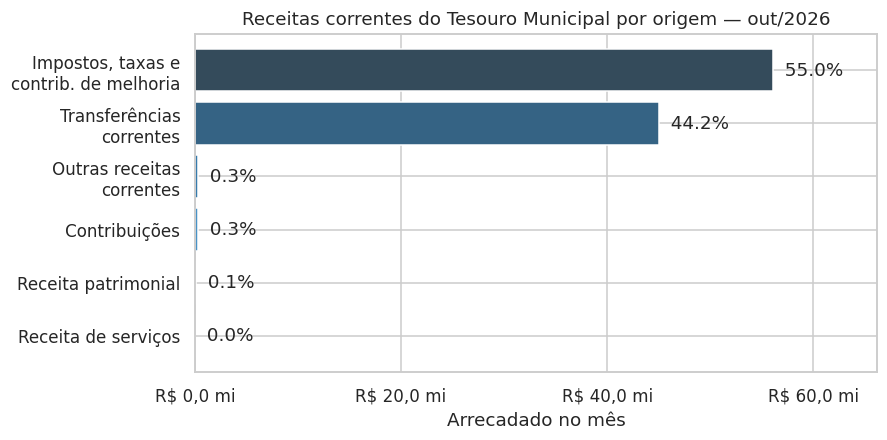

Conferência: soma das origens = R$ 101,9 mi | total do sistema = R$ 101,9 mi


In [11]:
origens = {"11": "Impostos, taxas e\ncontrib. de melhoria", "17": "Transferências\ncorrentes",
           "19": "Outras receitas\ncorrentes", "12": "Contribuições",
           "13": "Receita patrimonial", "16": "Receita de serviços"}
comp = pd.Series({rot: linha(c, 10)["valor_arrecado_mes"] for c, rot in origens.items()})
total_correntes = linha("1", 10)["valor_arrecado_mes"]
comp = comp.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(comp.index, comp.values, color=sns.color_palette("Blues_d", len(comp)))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(milhoes))
for b, v in zip(barras, comp.values):
    ax.text(v, b.get_y() + b.get_height()/2, f"  {v/total_correntes:.1%}", va="center")
ax.set_xlim(0, comp.max() * 1.18)
ax.xaxis.set_major_locator(mtick.MultipleLocator(20e6))
ax.set_title("Receitas correntes do Tesouro Municipal por origem — out/2026")
ax.set_xlabel("Arrecadado no mês")
salvar(fig, "g1_composicao_receitas.png")
plt.show()
print(f"Conferência: soma das origens = {milhoes(comp.sum())} | total do sistema = {milhoes(total_correntes)}")

**Frase de leitura:** em outubro/2026, a arrecadação própria (impostos, taxas e contribuições de melhoria) foi a maior fonte das receitas correntes do Tesouro, com pouco mais da metade do total, seguida de perto pelas transferências de outros entes; as demais origens somam menos de 1%. Isso mostra que **a arrecadação de tributos municipais, foco do nosso modelo, sustenta cerca de metade do caixa corrente da prefeitura**.

### Gráfico 2 — Evolução: setembro x outubro de 2026

Figura salva em docs/figuras/g2_evolucao_set_out.png


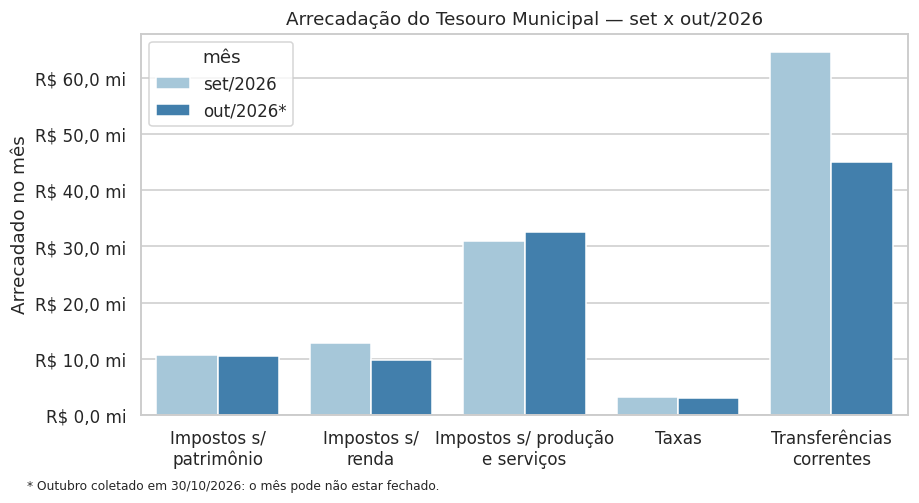

mês,out/2026*,set/2026,variação
item,,,
Impostos s/\npatrimônio,10557669.73,10687798.31,-1.2%
Impostos s/\nrenda,9820647.79,12762735.83,-23.1%
Impostos s/ produção\ne serviços,32625240.24,30934479.33,+5.5%
Taxas,3069834.35,3099436.77,-1.0%
Transferências\ncorrentes,45021285.24,64724724.17,-30.4%


In [12]:
itens = {"1112": "Impostos s/\npatrimônio", "1113": "Impostos s/\nrenda",
         "1114": "Impostos s/ produção\ne serviços", "112": "Taxas",
         "17": "Transferências\ncorrentes"}
evol = pd.DataFrame([{"item": rot, "mês": nome, "valor": linha(c, m)["valor_arrecado_mes"]}
                     for c, rot in itens.items() for m, nome in [(9, "set/2026"), (10, "out/2026*")]])

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=evol, x="item", y="valor", hue="mês", palette=["#9ecae1", "#3182bd"], ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(milhoes))
ax.set_xlabel(""); ax.set_ylabel("Arrecadado no mês")
ax.set_title("Arrecadação do Tesouro Municipal — set x out/2026")
fig.text(0.01, -0.04, "* Outubro coletado em 30/10/2026: o mês pode não estar fechado.", fontsize=8)
salvar(fig, "g2_evolucao_set_out.png")
plt.show()

var = evol.pivot(index="item", columns="mês", values="valor")
var["variação"] = (var["out/2026*"] / var["set/2026"] - 1).map("{:+.1%}".format)
var

**Frase de leitura:** de setembro para outubro, os impostos ficaram praticamente estáveis (exceto os impostos sobre renda, que caíram cerca de 23%), enquanto as transferências correntes caíram cerca de 30%. Como outubro foi coletado antes do fim do mês e temos **só dois pontos no tempo**, não é possível falar em tendência ou sazonalidade: para isso, a coleta precisa cobrir vários anos.

### Gráfico 3 — Distribuição dos valores arrecadados (linhas-folha, out/2026, todos os órgãos)

Figura salva em docs/figuras/g3_distribuicao_valores.png


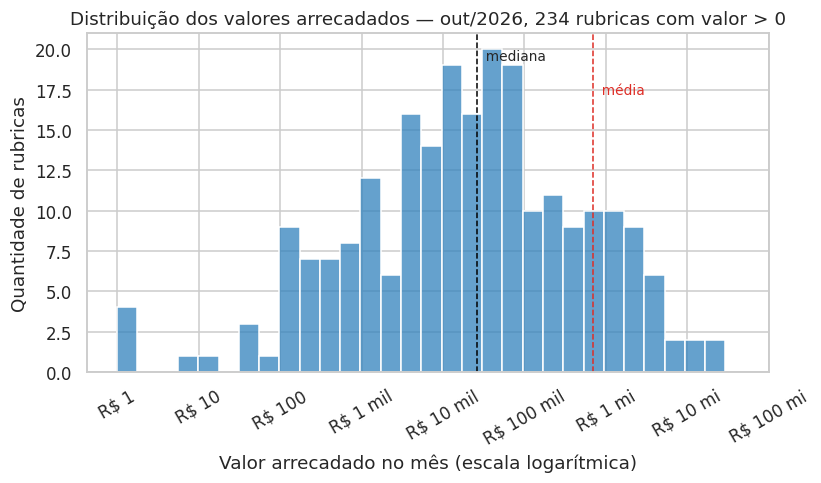

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(np.log10(folhas["valor_arrecado_mes"]), bins=30, color="#3182bd", ax=ax)
ax.axvline(np.log10(mediana), color="black", ls="--", lw=1)
ax.text(np.log10(mediana), ax.get_ylim()[1]*0.92, "  mediana", fontsize=9)
ax.axvline(np.log10(media), color="#de2d26", ls="--", lw=1)
ax.text(np.log10(media), ax.get_ylim()[1]*0.82, "  média", fontsize=9, color="#de2d26")
ticks = range(0, 9)
ax.set_xticks(list(ticks))
ax.set_xticklabels(["R$ 1", "R$ 10", "R$ 100", "R$ 1 mil", "R$ 10 mil", "R$ 100 mil",
                    "R$ 1 mi", "R$ 10 mi", "R$ 100 mi"], rotation=30)
ax.set_xlabel("Valor arrecadado no mês (escala logarítmica)")
ax.set_ylabel("Quantidade de rubricas")
ax.set_title(f"Distribuição dos valores arrecadados — out/2026, {len(folhas)} rubricas com valor > 0")
salvar(fig, "g3_distribuicao_valores.png")
plt.show()

**Frase de leitura:** os valores se espalham por quase oito ordens de grandeza (de alguns reais a dezenas de milhões), e a metade central das rubricas fica entre cerca de R$ 3 mil e R$ 190 mil. A média fica muito à direita da mediana por causa de poucos valores enormes. **Na Sprint 4, valores monetários deverão entrar no modelo em escala logarítmica** (como já faz `log_valor_debito` na engenharia de atributos).

### Gráfico 4 — Relação: arrecadado no mês x previsto para o mês

O `valor_orcado` é a previsão **anual**. Dividindo por 12, temos a expectativa de um mês médio; a razão arrecadado ÷ (orçado/12) mostra se a rubrica está acima ou abaixo do ritmo previsto.

Figura salva em docs/figuras/g4_relacao_orcado_arrecadado.png


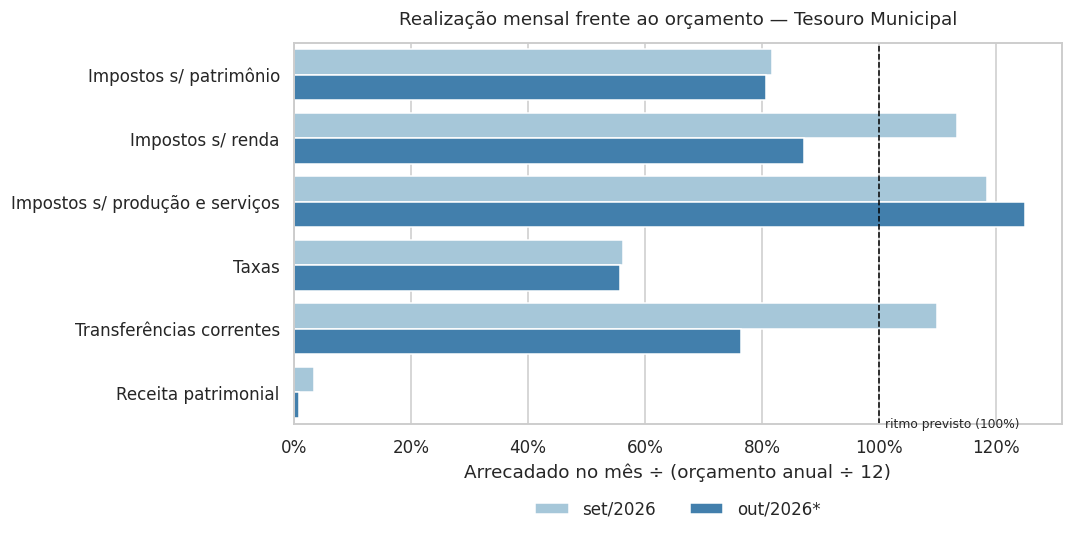

mês,out/2026*,set/2026
item,,
Impostos s/ patrimônio,81%,82%
Impostos s/ produção e serviços,125%,119%
Impostos s/ renda,87%,113%
Receita patrimonial,1%,3%
Taxas,56%,56%
Transferências correntes,76%,110%


In [14]:
itens_rel = {"1112": "Impostos s/ patrimônio", "1113": "Impostos s/ renda",
             "1114": "Impostos s/ produção e serviços", "112": "Taxas",
             "17": "Transferências correntes", "13": "Receita patrimonial"}
rel = pd.DataFrame([{"item": rot, "mês": nome,
                     "realizacao": linha(c, m)["valor_arrecado_mes"] / (linha(c, m)["valor_orcado"] / 12)}
                    for c, rot in itens_rel.items() for m, nome in [(9, "set/2026"), (10, "out/2026*")]])

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=rel, y="item", x="realizacao", hue="mês", palette=["#9ecae1", "#3182bd"], ax=ax)
ax.axvline(1, color="black", ls="--", lw=1)
ax.text(1.01, len(itens_rel) - 0.45, "ritmo previsto (100%)", fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Arrecadado no mês ÷ (orçamento anual ÷ 12)"); ax.set_ylabel("")
ax.set_title("Realização mensal frente ao orçamento — Tesouro Municipal", pad=12)
ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
salvar(fig, "g4_relacao_orcado_arrecadado.png")
plt.show()
rel.pivot(index="item", columns="mês", values="realizacao").map("{:.0%}".format)

**Frase de leitura:** nos dois meses, os impostos sobre patrimônio (cerca de 80%) e as taxas (cerca de 56%) ficaram **abaixo** do ritmo mensal previsto, os impostos sobre produção e serviços ficaram **acima** (cerca de 120%), e os impostos sobre renda e as transferências oscilaram (acima em setembro, abaixo em outubro); a receita patrimonial praticamente não se realizou. Parte dessas diferenças pode ser efeito de calendário (tributos como o IPTU costumam concentrar pagamentos em certas épocas do ano), o que reforça que **o modelo precisa de dados de vários meses e anos** para separar inadimplência de sazonalidade.

## 6. Conclusões e limitações

**O que os dados mostram**
1. Os tributos municipais respondem por cerca de metade das receitas correntes do Tesouro.
2. Os valores são extremamente assimétricos: transformação logarítmica é necessária na modelagem.
3. A realização frente ao orçamento varia muito entre tipos de receita.

**Limitações que precisam ser resolvidas antes da Sprint 4**
1. **Os dados não são de inadimplência.** São receitas agregadas, sem contribuinte, débito, vencimento ou localização. O modelo de predição de inadimplência exige uma base de débitos da dívida ativa (individual e anonimizada).
2. **Cobertura de menos de 2% da API** (`limite_paginas=3`): só set/out 2026, com setembro incompleto. Recomenda-se ampliar a coleta para vários anos.
3. **Outubro coletado antes do fim do mês**: comparações mensais ficam distorcidas. Recomenda-se coletar somente meses fechados.
4. **Hierarquia de códigos**: quem consumir a tabela `receitas_sefin_etl` deve somar só as folhas ou usar as linhas de total, nunca tudo.
5. **Colunas redundantes ou vazias** (`unidade_*`, `valor_arrecado_periodo`) podem ser removidas no ETL.